In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv(ROOT / "data" / "Cleaned" / "city_day_classification.csv", parse_dates=["Date"])

POLL = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
DATE_NUM = ["Month", "Weekday", "Is_Weekend", "Is_Winter", "Is_Diwali_Period"]
LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

X = pd.concat(
    [df[POLL + DATE_NUM], pd.get_dummies(df[["Season", "City"]], dtype=int)],
    axis=1,
)
y = df["AQI_Bucket_Code"]

train = df["Split"] == "Train"
X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("\nTrain class counts:\n", df[train]["AQI_Bucket"].value_counts().reindex(LABELS))
print("\nTest class counts:\n", df[~train]["AQI_Bucket"].value_counts().reindex(LABELS))

Train rows: 13326 | Test rows: 11475

Train class counts:
 AQI_Bucket
Good             396
Satisfactory    3683
Moderate        4844
Poor            1738
Very Poor       1711
Severe           954
Name: count, dtype: int64

Test class counts:
 AQI_Bucket
Good             939
Satisfactory    4519
Moderate        3969
Poor            1040
Very Poor        625
Severe           383
Name: count, dtype: int64


Load and pick features

In [2]:
models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    preds[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
    })

results = pd.DataFrame(rows).round(3)
results.to_csv(OUT / "classification_results.csv", index=False)
results

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Baseline (most frequent),0.346,0.058,0.167,0.086
1,Logistic Regression,0.719,0.666,0.638,0.644
2,Decision Tree,0.732,0.717,0.666,0.681
3,Random Forest,0.769,0.778,0.671,0.691


Train and score

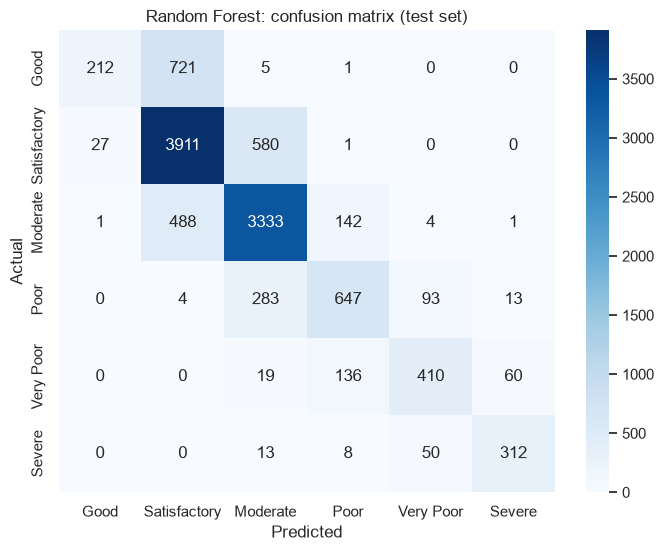

In [3]:
cm = confusion_matrix(y_test, preds["Random Forest"], labels=range(6))

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest: confusion matrix (test set)")
plt.savefig(OUT / "12_rf_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Confusion matrix (Random forest)

In [4]:
print(classification_report(y_test, preds["Random Forest"],
                            labels=range(6), target_names=LABELS, zero_division=0))

              precision    recall  f1-score   support

        Good       0.88      0.23      0.36       939
Satisfactory       0.76      0.87      0.81      4519
    Moderate       0.79      0.84      0.81      3969
        Poor       0.69      0.62      0.66      1040
   Very Poor       0.74      0.66      0.69       625
      Severe       0.81      0.81      0.81       383

    accuracy                           0.77     11475
   macro avg       0.78      0.67      0.69     11475
weighted avg       0.77      0.77      0.75     11475



Pre category report (Random forest)

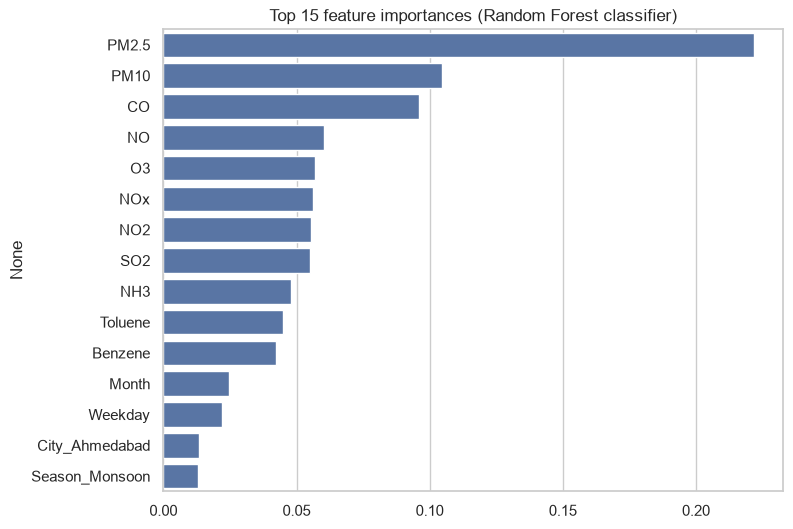

In [5]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Top 15 feature importances (Random Forest classifier)")
plt.savefig(OUT / "13_rf_clf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Feature Importance